# Comparing Policy Gradient Methods on MuJoCo
**CS778: Foundations of Modern AI** · Roll no. **230224**

This notebook implements three policy-gradient algorithms **from scratch** (PyTorch only, no RL libraries) and compares them on two MuJoCo locomotion tasks:

| Algorithm | Policy update | Lecture |
|---|---|---|
| **VPG** (Vanilla Policy Gradient / actor-critic) | one gradient-ascent step on $\sum_t \nabla\log\pi_\theta(A_t\mid S_t)\,\hat A_t$ | Policy Gradient, Variance Reduction |
| **TRPO** (Trust Region Policy Optimization) | natural-gradient step constrained to $\bar D_{KL} \le \delta$ (conjugate gradient + line search) | TRPO & PPO §5–8 |
| **PPO** (Proximal Policy Optimization, clip) | several epochs of minibatch ascent on the clipped surrogate | TRPO & PPO §9 |

All three share **the same** actor, critic, GAE advantage estimator, state normalization and training loop, so the *only* difference between them is the policy update rule.

**How to run:** top to bottom. The training cell skips any run whose results already exist in `results/`, so re-running the notebook only regenerates plots and videos. Deleting `results/` retrains everything (12 runs in parallel, ~30–60 min on a 16-core CPU).

**Notation** follows the lecture notes: state $S_t$, action $A_t$, reward $R_t$, value $V(S_t)$, TD residual $\delta_t$, advantage $\hat A_t$.

## 1. Setup

In [1]:
import gymnasium as gym, torch, numpy as np, mujoco
import random
import torch.nn as nn
torch.set_num_threads(1)   # tiny MLPs: one thread is much faster than PyTorch's default multithreading
print(gym.__version__, torch.__version__, mujoco.__version__)

0.29.1 2.14.0+cu130 3.14.0


### The environments
Both tasks have a 17-dimensional continuous state and a 6-dimensional continuous action (joint torques in $[-1, 1]$). Episodes are cut at 1000 steps.
- **HalfCheetah-v4**: reward = forward velocity − control cost. It can never fall, so every episode lasts exactly 1000 steps.
- **Walker2d-v4**: reward = forward velocity + a "healthy" bonus of +1 per step − control cost. The episode **terminates early** if the walker falls, so episode length is itself a measure of how well the agent has learned to balance.

In [2]:
for env_id in ["HalfCheetah-v4", "Walker2d-v4"]:
    env = gym.make(env_id)
    state, _ = env.reset(seed=0)
    print(env_id, "state:", env.observation_space.shape, "action:", env.action_space.shape)
    for _ in range(10):
        state, reward, terminated, truncated, _ = env.step(env.action_space.sample())
    env.close()
    

HalfCheetah-v4 state: (17,) action: (6,)
Walker2d-v4 state: (17,) action: (6,)


In [3]:
env = gym.make("HalfCheetah-v4", render_mode="rgb_array")
env.reset(seed=0)
print(env.render().shape)  # expect something like (480, 480, 3)

(480, 480, 3)


### Seeding
We fix Python, NumPy and PyTorch random generators so each run is reproducible. Different seeds give different network initializations and environment starts, letting us measure variability across runs.

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [5]:
set_seed(0)

In [6]:
print(np.random.rand(), torch.rand(1))

0.5488135039273248 tensor([0.4963])


## 2. Actor: a Gaussian policy $\pi_\theta(a \mid s)$
For continuous actions the policy outputs a diagonal Gaussian: an MLP (64-64, tanh) gives the mean $\mu_\theta(s)$, and a state-independent learned vector gives $\log\sigma$ (initialized to −0.5, so $\sigma \approx 0.61$).

$\log\pi_\theta(a\mid s)$ is the sum of the per-dimension log-densities. This is the quantity every policy-gradient estimator differentiates.

In [7]:
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.mean_net = nn.Sequential(
            nn.Linear(state_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, action_dim)
        )
        self.log_std = nn.Parameter(torch.full((action_dim,), -0.5))
    
    def dist(self, state):
        mean = self.mean_net(state)
        std = self.log_std.exp()
        dist = torch.distributions.Normal(mean, std)
        return dist

    def log_prob(self, dist, action):
        return dist.log_prob(action).sum(-1)
    
    # def forward(self, state):
    #     mean = self.mean_net(state)
    #     dist = torch.distributions.Normal(mean, self.log_std.exp())
    #     return dist

In [8]:
actor = Actor(17, 6)
state = torch.randn(5, 17)
d = actor.dist(state)
action = d.sample()
logp = actor.log_prob(d, action)
print(action.shape, logp.shape)
print(actor.log_std.exp())
print(len(list(actor.parameters())))

torch.Size([5, 6]) torch.Size([5])
tensor([0.6065, 0.6065, 0.6065, 0.6065, 0.6065, 0.6065],
       grad_fn=<ExpBackward0>)
7


## 3. Critic: the value function $f_w(s) \approx V^{\pi_\theta}(s)$
The critic is the function approximator from the Actor-Critic lecture (Part 4). It has the same 64-64 tanh architecture as the actor and outputs a single scalar.

In [9]:
class Critic(nn.Module):
    def __init__(self, state_dim):
        super().__init__()
        self.v_net = nn.Sequential(
            nn.Linear(state_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, state):
        return self.v_net(state).squeeze(-1)

In [10]:
critic = Critic(17)
value = critic(torch.randn(5, 17))
print(value.shape, len(list(critic.parameters())))

torch.Size([5]) 6


## 4. State normalization
MuJoCo state features have very different scales (positions vs. velocities). We keep a running mean/variance of every state seen, using the parallel-variance merge, and feed the networks $(s - \mu)/\sigma$ clipped to $[-10, 10]$. The test below checks that it recovers the mean 5 and std 3 of synthetic data.

In [11]:
class RunningMeanStd:
    def __init__(self, shape):
        self.mean  = np.zeros(shape)
        self.var   = np.ones(shape)
        self.count = 1e-4  

    def update(self, x):
        # x has shape (batch, state_dim)
        # steps below
        batch_mean = x.mean(axis=0)
        batch_var = x.var(axis=0)
        batch_count = x.shape[0]
        delta = batch_mean - self.mean
        total = self.count + batch_count
        new_mean = self.mean + delta * batch_count / total
        M2 = self.var * self.count + batch_var * batch_count + delta**2 * self.count * batch_count / total
        self.mean = new_mean
        self.var = M2 / total
        self.count = total

    def normalize(self, x):
        return np.clip((x - self.mean) / np.sqrt(self.var + 1e-8), -10, 10)

In [12]:
rms = RunningMeanStd((17,))
data = np.random.normal(5, 3, size=(10000, 17))
for i in range(0, 10000, 100):          # feed in chunks, like real training
    rms.update(data[i:i+100])
print(rms.mean[:3], np.sqrt(rms.var[:3]))
n = rms.normalize(data)
print(n.mean(), n.std())

[4.9787411  4.98268914 5.0427004 ] [2.98817081 2.96641892 3.00812517]
1.6721367320743037e-08 0.9999999899051148


## 5. Generalized Advantage Estimation (GAE)
From the Actor-Critic lecture (Part 6):

$$\delta_t = R_t + \gamma V(S_{t+1}) - V(S_t), \qquad \hat A_t^{\text{GAE}(\lambda)} = \sum_{l\ge 0} (\gamma\lambda)^l \delta_{t+l}$$

computed backwards with the recursion $\hat A_t = \delta_t + \gamma\lambda \hat A_{t+1}$ ($\gamma = 0.99$, $\lambda = 0.95$).

**Two different "episode over" flags** are needed because MuJoCo episodes can end for two reasons:

| Case | Bootstrap $V(S_{t+1})$ in $\delta_t$? | Keep summing future $\delta$'s? |
|---|---|---|
| normal step | yes | yes |
| **truncated** (1000-step time limit) | **yes**: the walker was fine and would have kept earning reward | no: the next buffer entry is a new episode |
| **terminated** (the walker fell) | no: $V(\text{terminal}) = 0$ | no |

So `terminated` controls the bootstrap and `ended = terminated or truncated` cuts the sum. Treating a time-limit cutoff as a fall would teach the critic that good states near step 1000 are worthless.

The critic's regression target is `ret = adv + value`, the λ-return. The rollout buffer stores one fixed-size batch of transitions and returns tensors for the update.

In [13]:
def compute_gae(reward, value, next_value, terminated, ended, gamma=0.99, lam=0.95):
    N = len(reward)
    adv = np.zeros(N, dtype=np.float32)
    last_adv = 0.0
    for t in reversed(range(N)):
        delta = reward[t] + gamma * (1 - terminated[t]) * next_value[t] - value[t]
        last_adv = delta + gamma * lam * (1 - ended[t]) * last_adv
        adv[t] = last_adv
    ret = adv + value            # adv + value
    return adv, ret

In [14]:
class RolloutBuffer:
    def __init__(self, size, state_dim, action_dim):
        self.state      = np.zeros((size, state_dim), dtype=np.float32)
        self.action     = np.zeros((size, action_dim), dtype=np.float32)
        self.logp       = np.zeros(size, dtype=np.float32)
        self.reward     = np.zeros(size, dtype=np.float32)
        self.value      = np.zeros(size, dtype=np.float32)
        self.next_value = np.zeros(size, dtype=np.float32)
        self.terminated = np.zeros(size, dtype=np.float32)
        self.ended      = np.zeros(size, dtype=np.float32)
        self.ptr = 0
        self.size = size

    def store(self, state, action, logp, reward, value, next_value, terminated, ended):
        self.state[self.ptr]      = state
        self.action[self.ptr]     = action
        self.logp[self.ptr]       = logp
        self.reward[self.ptr]     = reward
        self.value[self.ptr]      = value
        self.next_value[self.ptr] = next_value
        self.terminated[self.ptr] = terminated
        self.ended[self.ptr]      = ended
        self.ptr += 1

    def get(self, gamma=0.99, lam=0.95):
        adv, ret = compute_gae(self.reward, self.value, self.next_value,
                            self.terminated, self.ended, gamma, lam)
        self.ptr = 0
        t = lambda x: torch.as_tensor(x, dtype=torch.float32)
        return {
            "state":  t(self.state),
            "action": t(self.action),
            "logp":   t(self.logp),
            "adv":    t(adv),
            "ret":    t(ret),
        }

Sanity checks with $\gamma=\lambda=1$ (rewards all 1, values all 0), covering no termination, termination at $t=1$, and truncation at $t=1$ with $V(S_2)=5$:

In [15]:
z = np.zeros(3); r = np.ones(3)
e = np.array([0., 1., 0.]); nv = np.array([0., 5., 0.])
print(compute_gae(r, z, z, z, z, 1.0, 1.0)[0])    # expect [3. 2. 1.]
print(compute_gae(r, z, z, e, e, 1.0, 1.0)[0])    # expect [2. 1. 1.]  (terminated at t=1)
print(compute_gae(r, z, nv, z, e, 1.0, 1.0)[0])   # expect [7. 6. 1.]  (truncated at t=1)

[3. 2. 1.]
[2. 1. 1.]
[7. 6. 1.]


In [16]:
buf = RolloutBuffer(4, 17, 6)
for _ in range(4):
    buf.store(np.random.randn(17), np.random.randn(6), 0.0, 1.0, 0.0, 0.0, 0.0, 0.0)
print(buf.ptr)                                    # expect 4 (full)
data = buf.get()
print({k: v.shape for k, v in data.items()})      # state [4,17], action [4,6], others [4]
print(buf.ptr)                                    # expect 0 (reset)

4
{'state': torch.Size([4, 17]), 'action': torch.Size([4, 6]), 'logp': torch.Size([4]), 'adv': torch.Size([4]), 'ret': torch.Size([4])}
0


## 6. Logging and critic fitting
`Logger` records `(step, return, length)` at the end of every episode. These records become the learning curves. Returns are the **raw** environment rewards, not normalized ones.

`update_critic` fits $f_w$ to the λ-return targets with 80 full-batch Adam steps. The targets are computed once from the old critic before fitting, which is the "frozen target" of Actor-Critic §4.6. **All three algorithms use the identical critic update.**

In [17]:
import pandas as pd
import os

class Logger:
    def __init__(self):
        self.records = []

    def log(self, step, ep_return, ep_length):
        self.records.append({"step": step, "return": ep_return, "length": ep_length})

    def save(self, path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        pd.DataFrame(self.records).to_csv(path, index=False)

In [18]:
def update_critic(critic, v_opt, data, iters=80):
    for _ in range(iters):
        value = critic(data["state"])
        loss = ((value - data["ret"]) ** 2).mean()
        v_opt.zero_grad()
        loss.backward()
        v_opt.step()
    return loss.item()

## 7. Vanilla Policy Gradient (VPG)
The policy-gradient theorem with the advantage as the multiplier:

$$\hat G_\theta = \frac{1}{N}\sum_t \nabla_\theta \log\pi_\theta(A_t\mid S_t)\,\hat A_t$$

We minimize `-(logp * adv).mean()`, which is gradient **ascent** on $J$. It takes **one** Adam step per batch of 2048 steps. Advantages are normalized to mean 0 / std 1. Subtracting a constant is a valid baseline (Variance Reduction §7), and dividing by the std only rescales the step size.

In [19]:
def vpg_update(actor, critic, pi_opt, v_opt, data):
    state, action, adv = data["state"], data["action"], data["adv"]

    # 1. normalize advantages → mean 0, std 1
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)

    # 2. log π(a|s) under the CURRENT actor (with gradients on)
    d = actor.dist(state)
    logp = actor.log_prob(d, action)

    # 3. policy loss: minimizing -Σ log π · Â  =  ascent on Ĝ
    loss_pi = -(logp * adv).mean()

    # 4. one gradient step on the actor
    pi_opt.zero_grad()
    loss_pi.backward()
    pi_opt.step()

    # 5. fit the critic
    loss_v = update_critic(critic, v_opt, data)
    return loss_pi.item(), loss_v

## 8. Trust Region Policy Optimization (TRPO)
Solve (TRPO & PPO lecture §5–8)

$$\max_\theta\; g^\top(\theta-\theta_k) \quad \text{s.t.} \quad \tfrac12(\theta-\theta_k)^\top F (\theta-\theta_k) \le \delta$$

1. $g = \nabla_\theta L_{\theta_k}(\theta)\big|_{\theta_k}$, the gradient of the importance-sampled surrogate $L = \mathbb E[w\,\hat A]$.
2. $v \approx F^{-1}g$ by **conjugate gradient**, using only Fisher-vector products $Fv = \nabla\big((\nabla \bar D_{KL})^\top v\big)$ (double backprop). $F$ is never formed or inverted.
3. Full step $\sqrt{2\delta / g^\top v}\;v$ lands on the trust-region boundary ($\delta = 0.01$).
4. **Backtracking line search** shrinks the step by 0.8× until $\bar D_{KL} \le \delta$ *and* the surrogate actually improves. If no step passes, the policy is left unchanged.

We use $D_{KL}(\pi_{\theta_k}\,\|\,\pi_\theta)$. Its Hessian at $\theta_k$ is the same Fisher matrix as the reverse direction in the notes. A damping term $0.1\,v$ keeps CG stable.

In [20]:
from torch.nn.utils import parameters_to_vector, vector_to_parameters

def flat_grad(y, params, **kw):
    return torch.cat([g.reshape(-1) for g in torch.autograd.grad(y, params, **kw)])

def conjugate_gradient(Fvp, g, iters=10):
    # solves F x = g using only products F·v  (never forms F)
    x = torch.zeros_like(g)
    r, p = g.clone(), g.clone()
    rr = r @ r
    for _ in range(iters):
        Fp = Fvp(p)
        alpha = rr / (p @ Fp + 1e-8)
        x += alpha * p
        r -= alpha * Fp
        new_rr = r @ r
        if new_rr < 1e-10:
            break
        p = r + (new_rr / rr) * p
        rr = new_rr
    return x

def trpo_update(actor, critic, v_opt, data, delta=0.01, damping=0.1, backtrack_iters=10, backtrack_coef=0.8):
    state, action, logp_old, adv = data["state"], data["action"], data["logp"], data["adv"]
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    params = list(actor.parameters())
    with torch.no_grad():
        old_dist = actor.dist(state)                      # π_θk

    def surrogate():                                      # L_θk(θ) = E[ w · Â ]
        ratio = torch.exp(actor.log_prob(actor.dist(state), action) - logp_old)
        return (ratio * adv).mean()

    def mean_kl():                                        # D̄_KL, same Hessian (F) either direction
        return torch.distributions.kl_divergence(old_dist, actor.dist(state)).sum(-1).mean()

    def Fvp(v):                                           # F·v = ∇(∇KL · v), plus damping
        grad_kl = flat_grad(mean_kl(), params, create_graph=True)
        return flat_grad(grad_kl @ v, params) + damping * v

    # 1. g = ∇L at θk
    loss_old = surrogate()
    g = flat_grad(loss_old, params)

    # 2. v ≈ F⁻¹ g via conjugate gradient
    v = conjugate_gradient(Fvp, g)

    # 3. step to the trust-region boundary: sqrt(2δ / gᵀv) · v
    full_step = torch.sqrt(2 * delta / (g @ v + 1e-8)) * v

    # 4. backtracking line search on α: keep KL ≤ δ and require improvement
    theta_k = parameters_to_vector(params).detach()
    with torch.no_grad():
        for i in range(backtrack_iters):
            vector_to_parameters(theta_k + backtrack_coef**i * full_step, params)
            if mean_kl() <= delta and surrogate() > loss_old:
                break
        else:
            vector_to_parameters(theta_k, params)         # no acceptable step → stay at θk

    # 5. fit the critic
    loss_v = update_critic(critic, v_opt, data)
    return -loss_old.item(), loss_v

## 9. Proximal Policy Optimization (PPO-Clip)
PPO gets trust-region behaviour with first-order steps only (TRPO & PPO lecture §9), by clipping the probability ratio $w = \pi_\theta(a\mid s)/\pi_{\theta_k}(a\mid s)$:

$$L^{\varepsilon} = \mathbb E\Big[\min\big(w\,\hat A,\; \text{clip}(w, 1-\varepsilon, 1+\varepsilon)\,\hat A\big)\Big], \qquad \varepsilon = 0.2$$

The buffer's stored `logp` is $\log\pi_{\theta_k}$. Because the objective is flat once the ratio leaves $[1-\varepsilon, 1+\varepsilon]$ in the beneficial direction, the same batch can safely be reused for **10 epochs of 64-sample minibatches**. We also stop an epoch loop early if the approximate KL exceeds $1.5 \times 0.015$.

In [21]:
def ppo_update(actor, critic, pi_opt, v_opt, data, clip=0.2, epochs=10, minibatch=64, target_kl=0.015):
    state, action, logp_old, adv = data["state"], data["action"], data["logp"], data["adv"]
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    N = len(adv)

    for _ in range(epochs):
        idx = torch.randperm(N)
        for start in range(0, N, minibatch):
            mb = idx[start:start + minibatch]
            logp = actor.log_prob(actor.dist(state[mb]), action[mb])
            ratio = torch.exp(logp - logp_old[mb])                          # w_θk(θ, s, a)
            clipped = ratio.clamp(1 - clip, 1 + clip)
            loss_pi = -torch.min(ratio * adv[mb], clipped * adv[mb]).mean()  # -L^ε
            pi_opt.zero_grad()
            loss_pi.backward()
            pi_opt.step()

        # early stop once the policy has drifted too far from π_θk
        with torch.no_grad():
            approx_kl = (logp_old - actor.log_prob(actor.dist(state), action)).mean().item()
        if approx_kl > 1.5 * target_kl:
            break

    loss_v = update_critic(critic, v_opt, data)
    return loss_pi.item(), loss_v

## 10. Training loop
Each iteration collects a batch of 2048 environment steps with the current stochastic policy, then:
1. updates the state normalizer,
2. stores $(S_t, A_t, \log\pi, R_t, V(S_t), V(S_{t+1}), \text{terminated}, \text{ended})$,
3. computes GAE and calls the chosen algorithm's update.

Actions are sampled unclipped (so $\log\pi$ is exact) and clipped to $[-1,1]$ only when sent to the environment. At the end, the episode log goes to `results/<algo>_<env>_seed<k>.csv`, and the actor + normalizer statistics go to a `.pt` checkpoint (used for the videos).

| Hyperparameter | Value | | Hyperparameter | Value |
|---|---|---|---|---|
| batch (steps / update) | 2048 | | actor / critic lr (Adam) | 3e-4 / 1e-3 |
| $\gamma$, $\lambda$ | 0.99, 0.95 | | critic steps / update | 80 |
| TRPO $\delta$, damping, CG iters | 0.01, 0.1, 10 | | PPO $\varepsilon$, epochs, minibatch | 0.2, 10, 64 |

In [22]:
def train(algo, env_id, seed, total_steps=1_000_000, batch=2048, print_every=50):
    torch.set_num_threads(1)
    set_seed(seed)
    env = gym.make(env_id)
    state, _ = env.reset(seed=seed)
    state_dim, action_dim = env.observation_space.shape[0], env.action_space.shape[0]

    actor, critic = Actor(state_dim, action_dim), Critic(state_dim)
    pi_opt = torch.optim.Adam(actor.parameters(), lr=3e-4)
    v_opt  = torch.optim.Adam(critic.parameters(), lr=1e-3)
    state_rms, buf, logger = RunningMeanStd((state_dim,)), RolloutBuffer(batch, state_dim, action_dim), Logger()
    T = lambda x: torch.as_tensor(x, dtype=torch.float32)

    ep_ret, ep_len, step, n_updates = 0.0, 0, 0, 0
    while step < total_steps:
        # ---- COLLECT ----
        for _ in range(batch):
            state_rms.update(state[None])
            s = state_rms.normalize(state)
            with torch.no_grad():
                d = actor.dist(T(s)); action = d.sample()
                logp = actor.log_prob(d, action); value = critic(T(s))
            next_state, reward, terminated, truncated, _ = env.step(np.clip(action.numpy(), -1, 1))
            with torch.no_grad():
                next_value = critic(T(state_rms.normalize(next_state)))
            ended = terminated or truncated
            buf.store(s, action.numpy(), logp.item(), reward, value.item(), next_value.item(),
                      float(terminated), float(ended))

            ep_ret += reward; ep_len += 1; step += 1
            if ended:
                logger.log(step, ep_ret, ep_len)
                ep_ret, ep_len = 0.0, 0
                state, _ = env.reset()
            else:
                state = next_state

        # ---- PROCESS + UPDATE ----
        data = buf.get()
        if algo == "vpg":
            vpg_update(actor, critic, pi_opt, v_opt, data)
        elif algo == "trpo":
            trpo_update(actor, critic, v_opt, data)
        elif algo == "ppo":
            ppo_update(actor, critic, pi_opt, v_opt, data)
        n_updates += 1

        if logger.records and (n_updates % print_every == 0 or step >= total_steps):
            recent = [r["return"] for r in logger.records[-10:]]
            print(f"{algo:>4} {env_id} seed{seed} | step {step:>8} | avg return (last 10 eps) {np.mean(recent):8.1f}", flush=True)

    logger.save(f"results/{algo}_{env_id}_seed{seed}.csv")
    torch.save({"actor": actor.state_dict(), "mean": state_rms.mean,
                "var": state_rms.var, "count": state_rms.count},
               f"results/{algo}_{env_id}_seed{seed}.pt")
    env.close()
    return logger

## 11. Experiments: 3 algorithms × 2 environments × 2 seeds × 1M steps
The 12 runs are independent, so they run in parallel, one process per run. A run is skipped if its results file already covers the full 1M steps.

In [23]:
import multiprocessing as mp, time

ALGOS, ENVS, SEEDS = ["vpg", "trpo", "ppo"], ["HalfCheetah-v4", "Walker2d-v4"], [0, 1]
TOTAL_STEPS = 1_000_000

def is_done(algo, env_id, seed):
    csv = f"results/{algo}_{env_id}_seed{seed}.csv"
    return os.path.exists(csv) and pd.read_csv(csv)["step"].max() >= TOTAL_STEPS - 1000

def run(algo, env_id, seed):
    train(algo, env_id, seed, total_steps=TOTAL_STEPS)

jobs = [(a, e, s) for a in ALGOS for e in ENVS for s in SEEDS]
todo = [j for j in jobs if not is_done(*j)]
print(f"{len(jobs) - len(todo)} runs already finished, {len(todo)} to train")
t0 = time.time()
if todo:
    with mp.get_context("fork").Pool(min(len(todo), os.cpu_count())) as pool:
        pool.starmap(run, todo)
print(f"done in {(time.time() - t0) / 60:.1f} min")

12 runs already finished, 0 to train
done in 0.0 min


**Training log.** The runs above were trained earlier, and each saved every episode's `(step, return, length)` to `results/`. The cell below rebuilds the training log from those records, in the same format `train()` prints: the average return of the last 10 episodes at every 100k steps.

In [24]:
for algo in ALGOS:
    for env_id in ENVS:
        for seed in SEEDS:
            log = pd.read_csv(f"results/{algo}_{env_id}_seed{seed}.csv")
            for checkpoint in range(100_000, TOTAL_STEPS + 1, 100_000):
                recent = log[log["step"] <= checkpoint]["return"].tail(10)
                print(f"{algo:>4} {env_id} seed{seed} | step {checkpoint:>8} | avg return (last 10 eps) {recent.mean():8.1f}")
            print()

 vpg HalfCheetah-v4 seed0 | step   100000 | avg return (last 10 eps)   -141.7
 vpg HalfCheetah-v4 seed0 | step   200000 | avg return (last 10 eps)    -73.4
 vpg HalfCheetah-v4 seed0 | step   300000 | avg return (last 10 eps)     25.9
 vpg HalfCheetah-v4 seed0 | step   400000 | avg return (last 10 eps)    137.0
 vpg HalfCheetah-v4 seed0 | step   500000 | avg return (last 10 eps)    288.5
 vpg HalfCheetah-v4 seed0 | step   600000 | avg return (last 10 eps)    373.8
 vpg HalfCheetah-v4 seed0 | step   700000 | avg return (last 10 eps)    420.7
 vpg HalfCheetah-v4 seed0 | step   800000 | avg return (last 10 eps)    556.6
 vpg HalfCheetah-v4 seed0 | step   900000 | avg return (last 10 eps)    497.6
 vpg HalfCheetah-v4 seed0 | step  1000000 | avg return (last 10 eps)    582.5

 vpg HalfCheetah-v4 seed1 | step   100000 | avg return (last 10 eps)   -114.5
 vpg HalfCheetah-v4 seed1 | step   200000 | avg return (last 10 eps)     65.6
 vpg HalfCheetah-v4 seed1 | step   300000 | avg return (last 10

## 12. Results
**Learning curves.** Each episode's return and length is smoothed with a 10-episode moving average, then interpolated onto a common step grid. The line is the **mean over the 2 seeds**, and the shaded band spans the **min–max of the seeds**.

HalfCheetah can never fall, so its episode length is always exactly 1000 (the time limit) for every algorithm, and that panel is flat by construction. On Walker2d, episode length measures how long the walker stays upright.

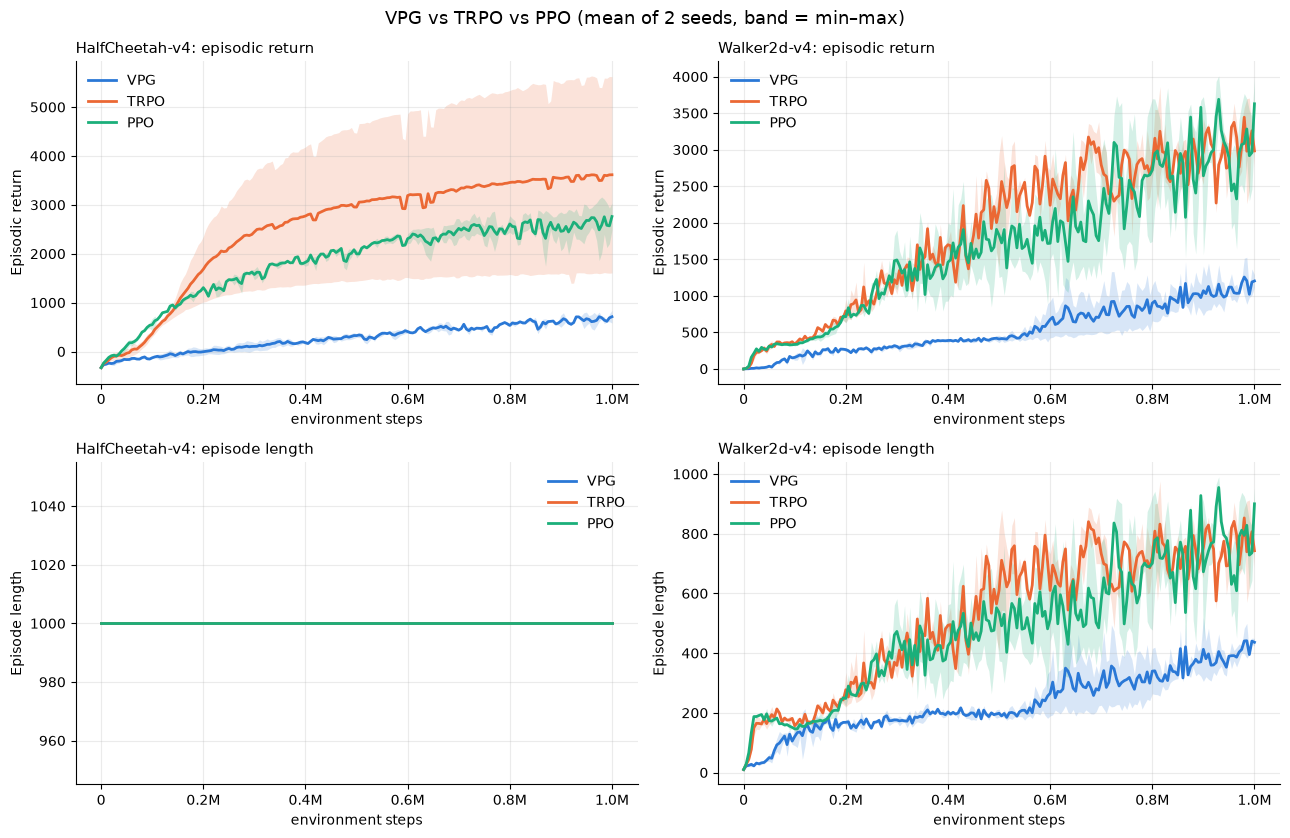

In [25]:
import matplotlib.pyplot as plt

COLORS = {"vpg": "#2a78d6", "trpo": "#eb6834", "ppo": "#1baf7a"}   # fixed per algorithm in every plot
GRID = np.linspace(0, TOTAL_STEPS, 201)

def load_curves(algo, env_id, metric, window=10):
    """One row per seed: the smoothed metric, interpolated onto GRID."""
    curves = []
    for seed in SEEDS:
        df = pd.read_csv(f"results/{algo}_{env_id}_seed{seed}.csv")
        smooth = df[metric].rolling(window, min_periods=1).mean()
        curves.append(np.interp(GRID, df["step"], smooth))
    return np.array(curves)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for col, env_id in enumerate(ENVS):
    for row, (metric, label) in enumerate([("return", "Episodic return"), ("length", "Episode length")]):
        ax = axes[row, col]
        for algo in ALGOS:
            c = load_curves(algo, env_id, metric)
            ax.plot(GRID, c.mean(0), color=COLORS[algo], lw=2, label=algo.upper())
            ax.fill_between(GRID, c.min(0), c.max(0), color=COLORS[algo], alpha=0.18, lw=0)
        ax.set_title(f"{env_id}: {label.lower()}", loc="left", fontsize=11)
        ax.set_xlabel("environment steps")
        ax.set_ylabel(label)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x else "0"))
        ax.grid(alpha=0.25)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.legend(frameon=False)
fig.suptitle("VPG vs TRPO vs PPO (mean of 2 seeds, band = min–max)", fontsize=13)
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/return_and_length.png", dpi=150, bbox_inches="tight")
plt.show()

**Individual seeds** (additional plot): each seed's return separately (10-episode moving average), to show how much of the band above is genuine seed-to-seed variation.

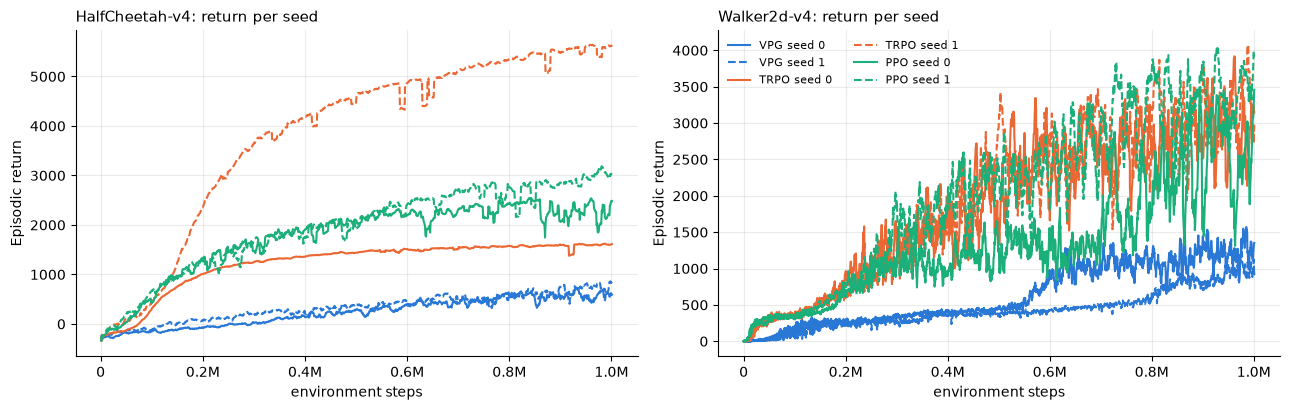

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, env_id in zip(axes, ENVS):
    for algo in ALGOS:
        for seed, style in zip(SEEDS, ["-", "--"]):
            df = pd.read_csv(f"results/{algo}_{env_id}_seed{seed}.csv")
            ax.plot(df["step"], df["return"].rolling(10, min_periods=1).mean(), style,
                    color=COLORS[algo], lw=1.5, label=f"{algo.upper()} seed {seed}")
    ax.set_title(f"{env_id}: return per seed", loc="left", fontsize=11)
    ax.set_xlabel("environment steps"); ax.set_ylabel("Episodic return")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x else "0"))
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("plots/return_per_seed.png", dpi=150, bbox_inches="tight")
plt.show()

**Final performance**: mean return (and length) of the last 10 training episodes of each run.

In [27]:
rows = []
for env_id in ENVS:
    for algo in ALGOS:
        dfs = [pd.read_csv(f"results/{algo}_{env_id}_seed{s}.csv").tail(10) for s in SEEDS]
        rets = [d["return"].mean() for d in dfs]
        rows.append({"env": env_id, "algo": algo.upper(),
                     **{f"return seed{s}": round(r, 1) for s, r in zip(SEEDS, rets)},
                     "mean return": round(np.mean(rets), 1),
                     "mean ep length": round(np.mean([d["length"].mean() for d in dfs]), 1)})
final = pd.DataFrame(rows)
final

,env,algo,return seed0,return seed1,mean return,mean ep length
0,HalfCheetah-v4,VPG,592.9,853.0,723.0,1000.0
1,HalfCheetah-v4,TRPO,1613.5,5604.0,3608.8,1000.0
2,HalfCheetah-v4,PPO,2483.0,3045.7,2764.3,1000.0
3,Walker2d-v4,VPG,1351.3,932.1,1141.7,426.5
4,Walker2d-v4,TRPO,3144.6,2971.6,3058.1,762.5
5,Walker2d-v4,PPO,3457.7,3909.8,3683.8,913.6


## 13. Videos of the trained policies
For each algorithm–environment pair we load the checkpoint of the better seed and run the policy **deterministically** (the Gaussian mean $\mu_\theta(s)$, no sampling noise) for 8 seconds. States are normalized with the statistics saved at the end of training.

In [28]:
import imageio

ROLL = "230224"
os.makedirs("videos", exist_ok=True)

def record_video(algo, env_id, seed, seconds=8):
    ckpt = torch.load(f"results/{algo}_{env_id}_seed{seed}.pt", weights_only=False)
    env = gym.make(env_id, render_mode="rgb_array")
    actor = Actor(env.observation_space.shape[0], env.action_space.shape[0])
    actor.load_state_dict(ckpt["actor"])
    rms = RunningMeanStd(env.observation_space.shape)
    rms.mean, rms.var = ckpt["mean"], ckpt["var"]

    fps = env.metadata["render_fps"]
    path = f"videos/{ROLL}_cs778_{algo}_{env_id}.mp4"
    state, _ = env.reset(seed=100)
    with imageio.get_writer(path, fps=fps, macro_block_size=1) as writer:
        for _ in range(seconds * fps):
            writer.append_data(env.render())
            with torch.no_grad():
                action = actor.dist(torch.as_tensor(rms.normalize(state), dtype=torch.float32)).mean.numpy()
            state, reward, terminated, truncated, _ = env.step(np.clip(action, -1, 1))
            if terminated or truncated:
                state, _ = env.reset()
    env.close()
    return path

for env_id in ENVS:
    for algo in ALGOS:
        best = final.query("env == @env_id and algo == @algo.upper()")[[f"return seed{s}" for s in SEEDS]].values.argmax()
        print(record_video(algo, env_id, SEEDS[best]))

videos/230224_cs778_vpg_HalfCheetah-v4.mp4


videos/230224_cs778_trpo_HalfCheetah-v4.mp4


videos/230224_cs778_ppo_HalfCheetah-v4.mp4


videos/230224_cs778_vpg_Walker2d-v4.mp4


videos/230224_cs778_trpo_Walker2d-v4.mp4


videos/230224_cs778_ppo_Walker2d-v4.mp4


## 14. Observations

**Final performance** (mean of the last 10 episodes, averaged over 2 seeds, after 1M steps):

| | VPG | TRPO | PPO |
|---|---|---|---|
| HalfCheetah-v4 | 723 | 3609 (seeds: 1614 / 5604) | 2764 (2483 / 3046) |
| Walker2d-v4 | 1142 | 3058 | **3684** |

1. **TRPO and PPO beat VPG by a wide margin on both tasks, and learn far faster.** At 250k steps, TRPO/PPO are at ~2100/1470 on HalfCheetah and ~940/1000 on Walker2d, while VPG is at 64 and 231. VPG takes a *single* small gradient step per 2048-step batch. Its step size must be kept small, because nothing stops a large step from wrecking the policy, so every sample buys very little progress. TRPO takes the *largest* step that keeps $\bar D_{KL} \le 0.01$ (a natural-gradient step, independent of how the network is parameterized). PPO reuses each batch for up to 10 epochs × 32 minibatches, and clipping stops those many small steps from drifting too far. Both extract much more improvement per sample, which is exactly the motivation for trust regions in the lecture.

2. **TRPO vs. PPO is not separable with 2 seeds.** On Walker2d the two are within noise for most of training, with PPO ahead at 1M. On HalfCheetah, TRPO's mean is higher, but its two seeds differ by 4000 points. **TRPO seed 0 flipped the cheetah onto its back** and learned to run upside down (97 m per episode vs. 324 m for seed 1). This is a well-known local optimum of HalfCheetah. A trust region controls *how fast* the policy changes, not *which* optimum it converges to. Once the policy commits to running on its back and its exploration noise shrinks, no small step leads back. PPO's two seeds ended much closer (2483 / 3046).

3. **Walker2d episode length tracks return.** Walker2d pays +1 per step for staying healthy and terminates on a fall, so learning to balance is most of the task. VPG walkers still fall after ~420 steps on average, while TRPO/PPO survive 700–900 steps, and ~1/3–1/2 of their final episodes reach the 1000-step limit. Walker2d curves are much noisier than HalfCheetah's for the same reason: a single stumble ends an episode early and cuts its return.

4. **Stability.** TRPO's HalfCheetah curves rise almost monotonically, since the line search rejects any step that does not improve the surrogate within the KL bound. PPO's constraint is soft (clipping plus approximate-KL early stopping), and its curves are slightly noisier, but it needs only first-order gradients: no Fisher-vector products, conjugate gradient or line search.